# 05 · Documentary and satellite comparison: Dos de Mayo, Curimaná (2019)
Case study before the model. Harmonization progress: 65 %.
Question: are there compatible detections near the locality and during the
reported interval? Neither the real number of fires nor global accuracy is estimated.
The place of the fire has no georeferenced perimeter in this analysis.

## 1. Independent sources and criteria fixed before looking at hotspots
INDECI, report 2027: page 1, start 31/08/2019 at 17:30; annex on page 4,
extinguished 02/09/2019 at 02:00. We read those times as Peru local time.
The report was published on 06/09: that date is not used as the date of the fire.
Source: https://portal.indeci.gob.pe/wp-content/uploads/2019/09/REPORTE-COMPLEMENTARIO-N%C2%BA-2027-06SEP2019-INCENDIO-FORESTAL-EN-EL-DISTRITO-DE-CURIMANA-UCAYALI-02.pdf

ANA, RD 103-2019, page 2: six riverbank vertices next to the village of Dos de
Mayo, WGS84 / UTM 18S. Their mean is used as the locality reference, NOT as the
point of the fire. The small INDECI map was inspected, but it does not allow
digitizing an exact GPS point with confidence.
Source: https://www.ana.gob.pe/sites/default/files/normatividad/files/001-RESOLUCI%C3%93N%20DIRECTORAL%20N%C2%B0%20103-2019-ANA-AAA.U.pdf

Main criterion: <=2 km from the reference during the reported interval.
Predefined sensitivity: radii of 1/2/5 km and time extensions of 0/6/24 h.
The radii are exploratory choices, not geographic confidence intervals.
All results are shown; a radius is not chosen because it gives matches.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer, Geod
from shapely import STRtree, points, box
from IPython.display import display
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name in {'notebooks', 'validacion'}:
    REPO_ROOT = REPO_ROOT.parent
ARTIFACTS = Path(os.environ.get('FIRMS_ARTIFACTS_DIR', str(REPO_ROOT / 'artifacts')))
PREP = ARTIFACTS / '02_preparacion'
OUT = ARTIFACTS / '06_caso_curimana'
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
river_vertices_utm18s = np.array([
    [482660.4140, 9065458.0780], [482641.4246, 9065498.1787],
    [482623.5230, 9065524.9980], [482610.0480, 9065566.6036],
    [482598.2548, 9065627.0039], [482583.9534, 9065675.8332]])
to_wgs84 = Transformer.from_crs('EPSG:32718', 'EPSG:4326', always_xy=True)
anchor_lon, anchor_lat = to_wgs84.transform(*river_vertices_utm18s.mean(axis=0))
start_local = pd.Timestamp('2019-08-31 17:30', tz='America/Lima')
end_local = pd.Timestamp('2019-09-02 02:00', tz='America/Lima')
start, end = start_local.tz_convert('UTC'), end_local.tz_convert('UTC')
spec = {
    'event_id': 'coen_2019_curimana_dos_de_mayo',
    'anchor_longitude': anchor_lon, 'anchor_latitude': anchor_lat,
    'anchor_kind': 'Mean of ANA riverbank vertices adjacent to locality, NOT fire coordinates',
    'anchor_fire_position_error_km': None,
    'start_local': str(start_local), 'end_local': str(end_local),
    'start_utc': str(start), 'end_utc': str(end),
    'timezone_assumption': 'Reported clock times interpreted as America/Lima',
    'primary_radius_m': 2000, 'radii_m': [1000, 2000, 5000],
    'temporal_margins_hours': [0, 6, 24], 'context_days': 7,
    'platforms': ['Aqua', 'Suomi-NPP'], 'processing': 'SP', 'type': 0,
    'status': 'exploratory neighborhood compatibility, no incident attribution',
}
spec_text = json.dumps(spec, ensure_ascii=False, indent=2)
(OUT / 'criterios_previos.json').write_text(spec_text, encoding='utf-8')
spec_hash = hashlib.sha256(spec_text.encode()).hexdigest()
print('Referencia de localidad:', round(anchor_lat, 5), round(anchor_lon, 5))
print('Intervalo local:', start_local, 'a', end_local)
print('Duración reportada:', (end-start).total_seconds()/3600, 'horas')

Referencia de localidad: -8.45354 -75.1579
Intervalo local: 2019-08-31 17:30:00-05:00 a 2019-09-02 02:00:00-05:00
Duración reportada: 32.5 horas


## 2. Read the original normalized detections
References to file and row are kept. The API is not queried again and
2024–2025 data are not used. Low confidence is not removed: it is reported separately.

In [3]:
def hash_file(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


def load_context():
    frames, hashes = [], []
    cols = ['source_member', 'source_row', 'timestamp_utc', 'platform', 'processing',
            'latitude_deg', 'longitude_deg', 'frp_mw', 'hotspot_type_code',
            'candidate_confidence_filter', 'confidence', 'daynight', 'scan', 'track']
    for stem in ['fire_archive_M-C61_848898', 'fire_archive_SV-C2_848901']:
        path = PREP / 'datos_normalizados' / f'{stem}_normalized.csv.gz'
        frame = pd.read_csv(path, usecols=cols, dtype={'confidence': 'string'})
        frame['timestamp_utc'] = pd.to_datetime(frame.timestamp_utc, utc=True)
        select = (frame.platform.isin(spec['platforms']) & frame.processing.eq('SP')
                  & frame.hotspot_type_code.eq(0)
                  & frame.timestamp_utc.between(start-pd.Timedelta(days=7), end+pd.Timedelta(days=7)))
        frames.append(frame.loc[select].copy())
        hashes.append({'file': path.name, 'sha256': hash_file(path)})
    return pd.concat(frames, ignore_index=True), hashes


context, data_hashes = load_context()
assert not context.duplicated(['source_member', 'source_row']).any()
print('Detecciones nacionales en ventana de contexto:', len(context))

Detecciones nacionales en ventana de contexto: 13691


## 3. R-tree for candidates and geodesic distance to confirm the radius
In this case study the tree indexes detections, not cells. It first narrows
the search with a rectangle; then the real WGS84 distance is checked.
The result is compared with an exhaustive search to verify the index.

In [4]:
geod = Geod(ellps='WGS84')
azimuths = np.arange(360)
ring_lon, ring_lat, _ = geod.fwd(np.full(360, anchor_lon), np.full(360, anchor_lat),
                                azimuths, np.full(360, 5000))
tree = STRtree(points(context.longitude_deg.to_numpy(), context.latitude_deg.to_numpy()))
query_box = box(ring_lon.min()-1e-5, ring_lat.min()-1e-5,
                ring_lon.max()+1e-5, ring_lat.max()+1e-5)
idx = tree.query(query_box, predicate='intersects')
candidates = context.iloc[idx].copy()
az, _, distance = geod.inv(np.full(len(candidates), anchor_lon),
                          np.full(len(candidates), anchor_lat),
                          candidates.longitude_deg.to_numpy(), candidates.latitude_deg.to_numpy())
candidates['distance_m'] = distance
candidates['east_km'] = distance*np.sin(np.radians(az))/1000
candidates['north_km'] = distance*np.cos(np.radians(az))/1000
nearby = candidates.loc[candidates.distance_m.le(5000)].copy()
_, _, all_dist = geod.inv(np.full(len(context), anchor_lon), np.full(len(context), anchor_lat),
                         context.longitude_deg.to_numpy(), context.latitude_deg.to_numpy())
assert set(nearby.index) == set(context.index[np.asarray(all_dist) <= 5000])
nearby['timestamp_local'] = nearby.timestamp_utc.dt.tz_convert('America/Lima')
nearby['in_reported_interval'] = nearby.timestamp_utc.between(start, end)
nearby = nearby.sort_values(['timestamp_utc', 'platform', 'distance_m'])
nearby.to_csv(OUT / 'detecciones_contexto_5km.csv', index=False)
print('Candidatos del rectángulo R-tree:', len(candidates), '| dentro de 5 km:', len(nearby))

Candidatos del rectángulo R-tree: 26 | dentro de 5 km: 22


## 4. Main result and all predefined sensitivities
Each number counts reported pixels, not independent fires.
Extending the period or the radius may include activity from other fires.

In [5]:
counts = []
for radius in spec['radii_m']:
    for margin in spec['temporal_margins_hours']:
        lo, hi = start-pd.Timedelta(hours=margin), end+pd.Timedelta(hours=margin)
        for sensor in spec['platforms']:
            hit = nearby.loc[nearby.platform.eq(sensor) & nearby.distance_m.le(radius)
                             & nearby.timestamp_utc.between(lo, hi)]
            counts.append({'radius_km': radius/1000, 'margin_hours': margin,
                           'platform': sensor, 'detections': len(hit),
                           'confidence_candidate_detections': int(hit.candidate_confidence_filter.sum())})
sensitivity = pd.DataFrame(counts)
sensitivity.to_csv(OUT / 'sensibilidad_espacio_tiempo.csv', index=False)
primary = nearby.loc[nearby.distance_m.le(2000) & nearby.in_reported_interval].copy()
primary.to_csv(OUT / 'candidatos_principales_2km.csv', index=False)
display(sensitivity[sensitivity.margin_hours.eq(0)])
display(primary[['platform', 'timestamp_local', 'distance_m', 'confidence', 'frp_mw',
                 'source_member', 'source_row']].round({'distance_m': 1}))

,radius_km,margin_hours,platform,detections,confidence_candidate_detections
0,1.0,0,Aqua,0,0
1,1.0,0,Suomi-NPP,0,0
6,2.0,0,Aqua,0,0
7,2.0,0,Suomi-NPP,7,7
12,5.0,0,Aqua,0,0
13,5.0,0,Suomi-NPP,7,7


,platform,timestamp_local,distance_m,confidence,frp_mw,source_member,source_row
8881,Suomi-NPP,2019-09-01 00:49:00-05:00,1052.6,n,6.08,fire_archive_SV-C2_848901.csv,525748
8895,Suomi-NPP,2019-09-01 00:49:00-05:00,1172.5,n,3.23,fire_archive_SV-C2_848901.csv,525762
8879,Suomi-NPP,2019-09-01 00:49:00-05:00,1209.2,n,3.23,fire_archive_SV-C2_848901.csv,525746
9703,Suomi-NPP,2019-09-01 13:26:00-05:00,1154.6,n,4.99,fire_archive_SV-C2_848901.csv,526575
9706,Suomi-NPP,2019-09-01 13:26:00-05:00,1243.0,n,4.99,fire_archive_SV-C2_848901.csv,526578
9697,Suomi-NPP,2019-09-01 13:26:00-05:00,1425.3,n,4.81,fire_archive_SV-C2_848901.csv,526569
9707,Suomi-NPP,2019-09-01 13:26:00-05:00,1620.5,n,3.94,fire_archive_SV-C2_848901.csv,526579


Seven VIIRS candidates were found: three on 01/09 at 00:49 and four
at 13:26, Peru time. All have nominal confidence. No Aqua
candidates were found under the main criterion. At 1 km there are no candidates and at
5 km the same seven remain during the reported interval.
This supports regional/temporal compatibility; not attribution to the same fire.

## 4b. Extra check against the original ZIP, if available
Coordinates, date-time, type and confidence of each candidate are compared.
It is explicitly skipped if the ZIP does not exist; it is never declared verified by default.

In [6]:
from zipfile import ZipFile
import csv
import io
ORIGINAL_DIR = Path(os.environ.get('FIRMS_INPUT_DIR', str(Path.home() / 'Downloads')))
original_zip = ORIGINAL_DIR / 'DL_FIRE_SV-C2_848901.zip'
original_zip_verified = None
if original_zip.exists() and len(primary):
    requested = set(primary.source_row.astype(int))
    found = {}
    with ZipFile(original_zip) as z:
        with z.open('fire_archive_SV-C2_848901.csv') as stream:
            for n, row in enumerate(csv.DictReader(io.TextIOWrapper(stream, encoding='utf-8-sig')), 1):
                if n in requested:
                    found[n] = row
                if n >= max(requested):
                    break
    assert set(found) == requested
    for _, record in primary.iterrows():
        raw = found[int(record.source_row)]
        assert np.isclose(float(raw['latitude']), record.latitude_deg, atol=1e-8, rtol=0)
        assert np.isclose(float(raw['longitude']), record.longitude_deg, atol=1e-8, rtol=0)
        clock = raw['acq_time'].zfill(4)
        raw_stamp = pd.Timestamp(raw['acq_date']+' '+clock[:2]+':'+clock[2:], tz='UTC')
        assert raw_stamp == record.timestamp_utc
        assert raw['confidence'] == record.confidence and raw['type'] == '0'
    original_zip_verified = True
    print(f'{len(primary)} candidatos cotejados con filas originales del ZIP FIRMS.')
else:
    print('Verificación adicional omitida: ZIP original no disponible o sin candidatos.')

7 candidatos cotejados con filas originales del ZIP FIRMS.


## 5. Relative location and timeline
The star represents the riverbank reference next to the locality. It is not
the confirmed origin of the fire. The 2 km circle is the exploratory criterion.
Nearby detections before and after are also shown, to avoid attributing
all the activity of the area to a single episode.

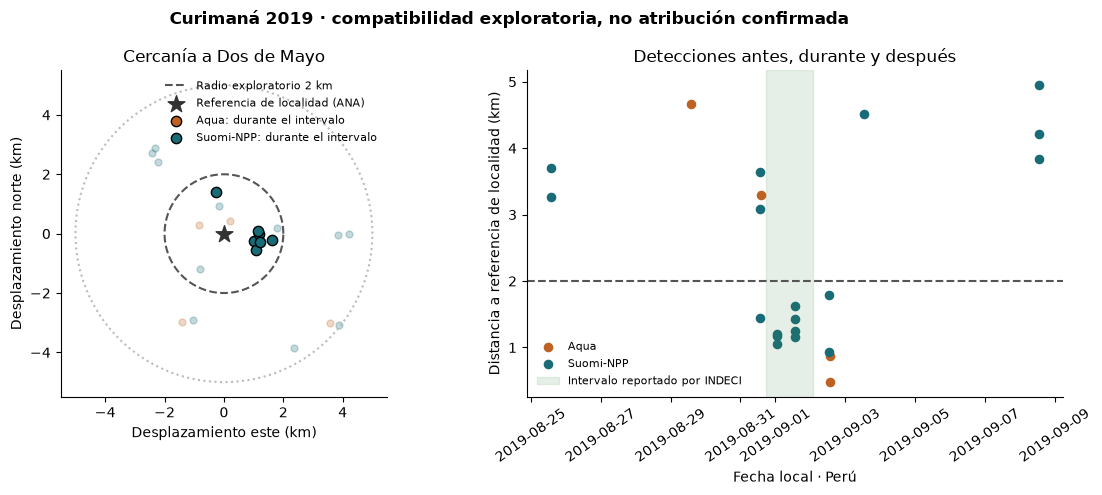

In [7]:
colors = {'Aqua': '#bd6223', 'Suomi-NPP': '#186b77'}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
angles = np.linspace(0, 2*np.pi, 361)
axes[0].plot(2*np.cos(angles), 2*np.sin(angles), '--', color='#555555', label='Radio exploratorio 2 km')
axes[0].plot(5*np.cos(angles), 5*np.sin(angles), ':', color='#bbbbbb')
axes[0].scatter([0], [0], marker='*', s=160, color='#333333', label='Referencia de localidad (ANA)')
for sensor, color in colors.items():
    other = nearby[nearby.platform.eq(sensor)]
    strict = primary[primary.platform.eq(sensor)]
    axes[0].scatter(other.east_km, other.north_km, s=25, color=color, alpha=.25)
    axes[0].scatter(strict.east_km, strict.north_km, s=55, color=color, edgecolor='black', label=f'{sensor}: durante el intervalo')
    axes[1].scatter(other.timestamp_local, other.distance_m/1000, s=35, color=color, label=sensor)
axes[0].set(aspect='equal', xlim=(-5.5,5.5), ylim=(-5.5,5.5),
            xlabel='Desplazamiento este (km)', ylabel='Desplazamiento norte (km)', title='Cercanía a Dos de Mayo')
axes[1].axvspan(start_local, end_local, alpha=.13, color='#438b48', label='Intervalo reportado por INDECI')
axes[1].axhline(2, linestyle='--', color='#555555')
axes[1].set(ylabel='Distancia a referencia de localidad (km)', xlabel='Fecha local · Perú',
            title='Detecciones antes, durante y después')
for ax in axes:
    ax.spines[['top','right']].set_visible(False)
    ax.legend(fontsize=8, loc='best', frameon=False)
axes[1].tick_params(axis='x', rotation=35)
fig.suptitle('Curimaná 2019 · compatibilidad exploratoria, no atribución confirmada', fontweight='bold')
fig.tight_layout()
plt.show()

## 6. What it allows us to conclude
A match would only be compatible with the reported locality and period.
We do not know the fire perimeter, the exact position of the fire or the
coverage/cloudiness of each overpass. A non-match stays undetermined;
it is not automatically read as a sensor omission.
This case does not validate the harmonization either: there is no fitted model yet.
The criteria are not changed after looking at the results.

In [8]:
summary = {
    'progress_harmonization_percent': 65, 'harmonized': False,
    'event_spec': spec, 'event_spec_sha256': spec_hash, 'data_sources': data_hashes,
    'context_national_rows': len(context), 'rtree_bbox_candidates': len(candidates),
    'context_rows_within_5km': len(nearby),
    'primary_counts_by_platform': {s: int(primary.platform.eq(s).sum()) for s in colors},
    'primary_min_distance_m': None if primary.empty else float(primary.distance_m.min()),
    'rtree_equals_exhaustive_geodesic_search': True,
    'conclusion': 'neighborhood_time_compatible_candidates' if len(primary) else 'no_candidates_in_prespecified_neighborhood_time_window',
    'confirmed_incident_attribution': False, 'sensor_omission_established': False,
    'coverage_known': False, 'georeferenced_fire_perimeter_available': False,
    'criteria_changed_after_inspecting_hotspots': False,
    'original_zip_candidates_verified': original_zip_verified,
}
for name in ['reporte_indeci_2027_2019.pdf', 'ana_rd103_2019.pdf']:
    path = OUT / 'fuentes' / name
    if path.exists():
        summary.setdefault('document_hashes', []).append({'file': name, 'sha256': hash_file(path)})
(OUT / 'resultado_curimana.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Resultado principal:', summary['primary_counts_by_platform'])
print('Atribución confirmada al incendio:', summary['confirmed_incident_attribution'])

Resultado principal: {'Aqua': 0, 'Suomi-NPP': 7}
Atribución confirmada al incendio: False
